## Photometric Reverberation Mapping

In **photometric** reverberation mapping (PRM), no band isolates the broad-line region (BLR). A broad-band filter that contains a strong emission line records the *sum* of the accretion-disk continuum, which varies promptly, and the line, which echoes the continuum after a delay. Modeling such a band as a pure time shift (as in the Reverberation Mapping tutorial) is wrong: most of the band's flux has no delay at all.

This notebook builds a GP kernel in which every band is a mixture of a prompt continuum and a delayed, smoothed BLR response, all driven by one latent process:

1. **The math**: the covariance of mixed bands, and why an **Erlang** transfer function turns the BLR convolution into a small linear state-space model. That keeps the GP likelihood $\mathcal{O}(N)$.
2. **A kernel for any base process**: `MixedBLRKernel` wraps *any* quasiseparable EzTaoX/`tinygp` kernel (DRW, SHO, CARMA, sums, ...) as the latent driver.
3. **SDSS-RM test**: using the public light curves of SDSS-RM quasar RM160, we build a synthetic photometric band, *continuum + H$\beta$*, with a known line-to-continuum flux ratio. We then check that the mixed model recovers the spectroscopic lag, and show that a pure-shift model does not.

The SDSS-RM data are downloaded from the [final-result page](https://ariel.astro.illinois.edu/sdssrm/final_result/) ([Shen et al. 2024](https://ui.adsabs.harvard.edu/abs/2024ApJS..272...26S)), so the notebook needs internet access.

### 0. Installation note: this notebook needs the GitHub version of `tinygp`

The mixed kernel is **not time-reversible**: the BLR responds to the continuum's past, not its future. Quasiseparable kernels with a non-reversible state transition need the corrected transition convention in `tinygp`'s development version; the current `tinygp` release assumes reversibility. Until the next release:

```
pip install -U "git+https://github.com/dfm/tinygp"
```

In [1]:
import urllib.request

import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

mpl.rcParams.update(
    {
        "text.usetex": False,
        "axes.labelsize": 20,
        "figure.labelsize": 18,
        "xtick.labelsize": 16,
        "ytick.labelsize": 16,
        "figure.constrained_layout.wspace": 0,
        "figure.constrained_layout.hspace": 0,
        "figure.constrained_layout.h_pad": 0,
        "figure.constrained_layout.w_pad": 0,
        "axes.linewidth": 1.2,
    }
)

import jax
import jax.numpy as jnp

# you should always set this
jax.config.update("jax_enable_x64", True)

import equinox as eqx
import numpyro
import numpyro.distributions as dist
import tinygp
import tinygp.kernels.quasisep as tkq
import eztaox

print(f"eztaox {eztaox.__version__} | tinygp {tinygp.__version__} | numpyro {numpyro.__version__} | jax {jax.__version__}")

eztaox 0.2.0 | tinygp 0.3.2.dev17+g103b634a6 | numpyro 0.19.0 | jax 0.6.2


### 1. The math

#### 1.1 Mixed bands

Let $x(t)$ be the latent continuum variability, a stationary GP with autocovariance $k_x(\tau)$. The BLR reprocesses it through a causal transfer function $\psi(u)$ ($\psi=0$ for $u<0$, $\int\psi\,du=1$):

$$
\ell(t) = (\psi * x)(t) = \int_0^\infty \psi(u)\, x(t-u)\, du .
$$

The fractional flux variation observed in band $b$ is a mixture of the two,

$$
y_b(t) = c_b\, x(t) + r_b\, \ell(t),
$$

where $c_b$ and $r_b$ are the continuum and BLR amplitudes in band $b$. A pure continuum band has $r_b=0$, a spectroscopic line light curve has $c_b=0$, and a photometric band containing a broad line has both. For two bands $b$ and $b'$ separated by $\Delta = t' - t$, the covariance is

$$
\begin{aligned}
\mathrm{Cov}\left[y_b(t), y_{b'}(t+\Delta)\right] =\;
& c_b c_{b'}\, k_x(\Delta)
+ c_b r_{b'} \int_0^\infty \psi(u)\, k_x(\Delta-u)\, du \\
&+ r_b c_{b'} \int_0^\infty \psi(u)\, k_x(\Delta+u)\, du
+ r_b r_{b'} \iint \psi(u)\psi(v)\, k_x(\Delta-u+v)\, du\, dv .
\end{aligned}
$$

The two middle terms are **not symmetric in $\Delta$**: the line correlates with the continuum's past. That asymmetry carries the lag information. In a mixed band the lag shows up only through these cross terms and through the BLR smoothing of the band's own autocovariance, never as a simple shift of the whole band.

#### 1.2 Why an Erlang transfer function?

Evaluating those convolution integrals for every pair of observations gives a dense $N\times N$ covariance matrix and an $\mathcal{O}(N^3)$ likelihood. The trick is to choose a transfer function that a few linear ODEs can generate. The **Erlang** (integer-shape gamma) distribution

$$
\psi_K(u) = \frac{u^{K-1}\, e^{-u/\theta}}{(K-1)!\,\theta^K}, \qquad u \ge 0,
\qquad \text{mean lag } \bar\tau = K\theta, \qquad \frac{\text{rms width}}{\bar\tau} = \frac{1}{\sqrt{K}},
$$

has Laplace transform $\hat\psi_K(s) = (1+\theta s)^{-K}$. That is the transfer function of $K$ **identical first-order low-pass filters in series**:

$$
\frac{ds_1}{dt} = \frac{x - s_1}{\theta}, \qquad
\frac{ds_j}{dt} = \frac{s_{j-1} - s_j}{\theta}\;\; (j=2,\dots,K), \qquad
\ell(t) = s_K(t).
$$

Each filter is a linear ODE, so the chain adds just $K$ states to whatever state-space model generates $x(t)$. $K$ sets the shape: $K=1$ is a one-sided exponential, larger $K$ is more peaked, and $K\to\infty$ approaches a pure delay. We use $K=3$ by default.

#### 1.3 The augmented state-space model

Every quasiseparable `tinygp`/EzTaoX kernel is the covariance of a linear stochastic differential equation, $d\mathbf z = F\mathbf z\,dt + d\mathbf w$, observed as $x = \mathbf h^\top \mathbf z$, with stationary state covariance $P_x$. The process noise is implied by $P_x$: $Q_x = -(F P_x + P_x F^\top)$. This includes the DRW (one state), the SHO (two states), CARMA($p,q$) ($p$ states), and sums of them. Stacking $\mathbf Z = (\mathbf z, s_1,\dots,s_K)$ gives one linear SDE:

$$
A = \begin{pmatrix}
F & 0 \\
\frac{1}{\theta}\,\mathbf e_1 \mathbf h^\top & \frac{1}{\theta}(J - I)
\end{pmatrix}, \qquad
Q = \begin{pmatrix} Q_x & 0 \\ 0 & 0 \end{pmatrix},
$$

where $J$ has ones on the first sub-diagonal. Every band is a linear readout of this single Markov state, $y_b = \mathbf H_b^\top \mathbf Z$, with $\mathbf H_b = (c_b \mathbf h, 0, \dots, 0, \tilde r_b)$. All bands together therefore have a quasiseparable covariance, and `tinygp` evaluates the likelihood in $\mathcal{O}(N)$:

- **Stationary covariance**: $P$ solves the Lyapunov equation $A P + P A^\top + Q = 0$.
- **Transition between observation times**: $\Phi(\Delta) = e^{A\Delta}$, a small matrix exponential.
- **Cross-covariance** ($\Delta \ge 0$): $\mathrm{Cov}[y_b(t), y_{b'}(t+\Delta)] = \mathbf H_{b'}^\top\, e^{A\Delta} P\, \mathbf H_b$.

#### 1.4 A closed-form transition matrix

Calling a matrix exponential for every pair of consecutive observations is slow, especially inside gradients. Because $A$ is block-lower-triangular, $A = \begin{pmatrix} F & 0 \\ D & C\end{pmatrix}$ with $D = \frac{1}{\theta}\mathbf e_1\mathbf h^\top$ and $C=\frac{1}{\theta}(J-I)$, we can block-diagonalize it. If $X$ solves the Sylvester equation $C X - X F = D$, then

$$
e^{A\Delta} = \begin{pmatrix} \Phi_F(\Delta) & 0 \\ \Phi_C(\Delta)\,X - X\,\Phi_F(\Delta) & \Phi_C(\Delta) \end{pmatrix}.
$$

- $\Phi_F$ is the base kernel's own (analytic) transition matrix.
- $\Phi_C$, the Erlang chain's transition, is lower-triangular Toeplitz: $[\Phi_C]_{j,j-k} = e^{-\Delta/\theta}\,(\Delta/\theta)^k/k!$.
- Row by row, the Sylvester equation is a short recursion, $X_j\,(\theta^{-1} I + F) = \theta^{-1} X_{j-1} - D_j$. It is solved once per kernel evaluation, not once per observation.

This is exact, and it works for any base kernel whose spectrum does not contain $-1/\theta$. Equality happens only on a set of measure zero (e.g., a DRW with timescale exactly $\theta = \bar\tau/K$). The matrix exponential would handle that case too, but it is several times slower.

We normalize $\tilde r_b = r_b\,\sigma_x/\sigma_\ell$ (the stationary rms of $x$ and $\ell$), so that $r_b/c_b$ is the BLR-to-continuum ratio of *variability amplitudes* in band $b$, whatever the base kernel. $A$ is lower block-triangular and not time-reversible, which is why the GitHub `tinygp` is needed.

### 2. `MixedBLRKernel`: Erlang BLR response on any base kernel

The model of Section 1 is implemented as `eztaox.kernels.quasisep.MixedBLRKernel`. It follows the `MultibandLowRank` pattern: it receives a dictionary of `params` (`lag`, and per-band `amp_cont` and `amp_blr`) and a base `kernel`, and it can be passed to `MultiVarModel` as `multiband_kernel`. Internally it builds the augmented generator $A$, solves the Lyapunov equation for $P$, and uses the closed-form transition of Section 1.4. The base kernel only needs `design_matrix`, `stationary_covariance`, `observation_model`, and `transition_matrix`, which every quasiseparable kernel provides.

In [2]:
from eztaox.kernels.quasisep import MixedBLRKernel

#### 2.1 Check against direct numerical convolution

Before using the kernel, we verify it against the integrals in Section 1.1, evaluated numerically, for both a DRW and an SHO base kernel. We also check the closed-form transition against `jax.scipy.linalg.expm`. We take a continuum band ($c_0=1, r_0=0$) and a mixed band ($c_1=0.8, r_1=0.5$).

In [3]:
from scipy.stats import gamma as gamma_dist
from eztaox.kernels.quasisep import Exp, SHO

lag_true, K = 60.0, 3
u = np.linspace(0.0, 1500.0, 6001)
du = u[1] - u[0]
psi = gamma_dist.pdf(u, K, scale=lag_true / K)
check_params = {"lag": jnp.asarray(lag_true), "amp_cont": jnp.array([1.0, 0.8]), "amp_blr": jnp.array([0.0, 0.5])}

for name, base in [("DRW", Exp(scale=150.0, sigma=0.3)), ("SHO", SHO(omega=2 * np.pi / 300, quality=0.4, sigma=0.3))]:
    k_x = lambda d: np.asarray(
        jax.vmap(lambda x: base.evaluate(jnp.zeros(()), x))(jnp.atleast_1d(jnp.asarray(d, float)))
    ).reshape(np.shape(d))
    kern = MixedBLRKernel(params=check_params, kernel=base, order=K)
    # rms of the BLR term: double integral of k_x against psi
    UU = (u[:, None] - u[None, :])[::5, ::5]
    var_l = (k_x(UU.ravel()).reshape(UU.shape) * psi[::5, None] * psi[None, ::5]).sum() * (5 * du) ** 2
    r_tilde = 0.5 * np.sqrt(k_x(0.0) / var_l)
    max_err = 0.0
    for d in [-200.0, -60.0, 0.0, 30.0, 60.0, 200.0]:
        ref = 0.8 * k_x(d) + r_tilde * (k_x(d - u) * psi).sum() * du
        X0, X1 = (jnp.asarray(0.0), jnp.asarray(0)), (jnp.asarray(abs(d)), jnp.asarray(1))
        val = kern.evaluate(X0, X1) if d >= 0 else kern.evaluate((jnp.asarray(abs(d)), jnp.asarray(0)), (jnp.asarray(0.0), jnp.asarray(1)))
        max_err = max(max_err, abs(float(val) - float(ref)) / float(k_x(0.0)))
    A = kern.design_matrix()
    expm_err = max(float(jnp.max(jnp.abs(kern.transition_matrix((jnp.asarray(0.0), 0), (jnp.asarray(d), 0)).T
                                         - jax.scipy.linalg.expm(A * d)))) for d in [1.0, 60.0, 600.0])
    print(f"{name}: max |kernel - numerical convolution| / variance = {max_err:.1e}; "
          f"max |closed-form transition - expm| = {expm_err:.1e}")

DRW: max |kernel - numerical convolution| / variance = 4.4e-06; max |closed-form transition - expm| = 2.5e-16


SHO: max |kernel - numerical convolution| / variance = 2.2e-08; max |closed-form transition - expm| = 1.6e-13


The small residual comes from the coarse grid used for the numerical double integral. Next, we plot what the kernel implies for the continuum band and the mixed band. The cross-covariance (right) peaks at a positive separation and is asymmetric: the mixed band "remembers" the continuum's past.

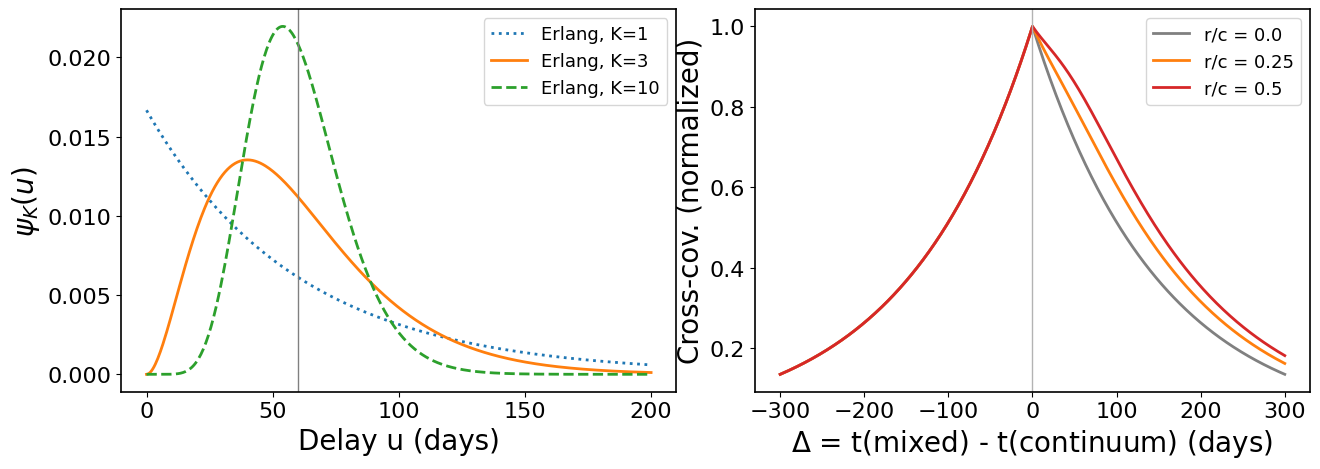

In [4]:
base = Exp(scale=150.0, sigma=0.3)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
tt = np.linspace(0, 200, 400)
for Kk, ls in [(1, ":"), (3, "-"), (10, "--")]:
    axes[0].plot(tt, gamma_dist.pdf(tt, Kk, scale=lag_true / Kk), ls=ls, lw=2, label=f"Erlang, K={Kk}")
axes[0].axvline(lag_true, color="0.5", lw=1)
axes[0].set_xlabel("Delay u (days)")
axes[0].set_ylabel(r"$\psi_K(u)$")
axes[0].legend(fontsize=13)

dd = np.linspace(-300, 300, 601)
for amp_blr, color in [(0.0, "0.5"), (0.25, "tab:orange"), (0.5, "tab:red")]:
    kern = MixedBLRKernel(params={"lag": jnp.asarray(lag_true), "amp_cont": jnp.array([1.0, 1.0]),
                                  "amp_blr": jnp.array([0.0, amp_blr])}, kernel=base, order=3)
    cov = [float(kern.evaluate((jnp.asarray(max(-d, 0.0)), jnp.asarray(0)), (jnp.asarray(max(d, 0.0)), jnp.asarray(1))))
           for d in dd]
    cov = np.array(cov)
    axes[1].plot(dd, cov / cov.max(), color=color, lw=2, label=f"r/c = {amp_blr}")
axes[1].axvline(0, color="0.7", lw=1)
axes[1].set_xlabel(r"$\Delta$ = t(mixed) - t(continuum) (days)")
axes[1].set_ylabel("Cross-cov. (normalized)")
axes[1].legend(fontsize=13);

### 3. Data: SDSS-RM continuum and a synthetic photometric band

We download RM160's continuum and broad H$\beta$ light curves, as in the spectroscopic lag tutorial. Its published H$\beta$ lag is $69.8^{+2.9}_{-2.7}$ observed-frame days.

To mimic PRM, we build a **mixed band** from the same data: at a continuum epoch $t$ inside the H$\beta$ campaign, we interpolate H$\beta$ (only between line epochs less than 30 days apart) and form the flux-weighted fractional variation

$$
y_\mathrm{mix}(t) = \frac{\delta_C(t) + a\, \delta_{H\beta}(t)}{1 + a},
$$

where $\delta = F/\mathrm{median}(F) - 1$ for each light curve and $a$ is the **line-to-continuum flux ratio** in the band. Continuum epochs inside the campaign are split alternately between the continuum band and the mixed band, so the two bands never share a measurement or its noise.

#### Why the mixing is done in flux

The continuum and the line **add in flux**, not in magnitudes. With median fluxes $\bar C$ and $\bar L$ in the band, the band flux is

$$
F_\mathrm{mix}(t) = C(t) + L(t) = \bar C\,[1+\delta_C(t)] + \bar L\,[1+\delta_{H\beta}(t)] .
$$

Dividing by $\bar C + \bar L$ and subtracting 1 gives the fractional variation of the band,

$$
\frac{F_\mathrm{mix}(t)}{\bar C + \bar L} - 1 = \frac{\delta_C(t) + a\,\delta_{H\beta}(t)}{1+a}, \qquad a = \bar L/\bar C ,
$$

which is the formula above, with errors combined in quadrature using the same weights. The only approximation is using medians as the reference fluxes. Working in fractional variations also removes units: the SDSS-RM continuum is a flux density ($f_\nu$) and the H$\beta$ light curve an integrated line flux, but only their *relative* variations and the ratio $a$ enter.

The GP model is linear in the same way: $y_b = c_b\,x + r_b\,\ell$ in Section 1.1 is a sum of fluxes. That linearity makes the covariance a sum of four terms, and it lets every band be read out of one linear state-space model. **Magnitudes do not add**, so a mixed-band model fit directly to magnitudes is not exact.

#### If your light curves are in magnitudes

Survey photometry usually comes as magnitudes. Convert each band to fractional flux before fitting,

$$
y = \frac{F}{\bar F} - 1 = 10^{-0.4\,(m-\bar m)} - 1, \qquad
\sigma_y \approx \frac{\ln 10}{2.5}\,(1+y)\,\sigma_m ,
$$

where $\bar m$ is a reference magnitude for the band, e.g., its median. For small variations $y \approx -0.921\,(m-\bar m)$, so the magnitude light curve is nearly linear in flux. For large-amplitude variability, or bands with strong lines, convert explicitly.

{'cont': 650, 'mix': 226}


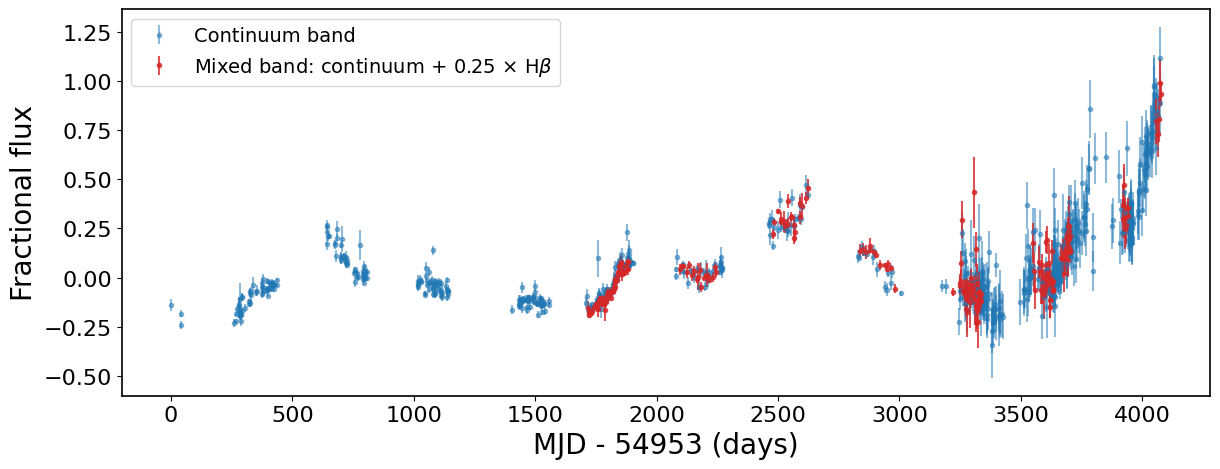

In [5]:
URL = "https://ariel.astro.illinois.edu/sdssrm/final_result/rm{rmid:03d}/{name}"


def load_sdssrm_lc(rmid, name):
    # Download one SDSS-RM light curve; return MJD, fractional flux, and its error
    text = urllib.request.urlopen(URL.format(rmid=rmid, name=name)).read().decode()
    rows = np.array([[float(v) for v in line.split()[:3]] for line in text.splitlines()
                     if line.strip() and not line.startswith("#")])
    rows = rows[np.isfinite(rows).all(axis=1) & (rows[:, 2] > 0)]
    rows = rows[np.argsort(rows[:, 0])]
    scale = np.median(rows[:, 1])
    return rows[:, 0], rows[:, 1] / scale - 1.0, rows[:, 2] / scale


rmid, z = 160, 0.3598
ref_lag, ref_lo, ref_hi = 69.8, 2.7, 2.9  # SDSS-RM adopted Hbeta lag (observed frame)
t_cont, y_cont, e_cont = load_sdssrm_lc(rmid, "cont_lc.txt")
t_hb, y_hb, e_hb = load_sdssrm_lc(rmid, "hb_lc.txt")
t_ref = t_cont.min()


def make_prm_band(a, max_gap=30.0):
    # Split continuum epochs into a continuum band (0) and a continuum + a * Hbeta band (1)
    j = np.searchsorted(t_hb, t_cont)
    jl, jr = np.clip(j - 1, 0, t_hb.size - 1), np.clip(j, 0, t_hb.size - 1)
    gap = t_hb[jr] - t_hb[jl]
    covered = (j > 0) & (j < t_hb.size) & (gap > 0) & (gap <= max_gap)
    w = np.where(covered, (t_cont - t_hb[jl]) / np.where(gap > 0, gap, 1.0), 0.0)
    y_line = (1 - w) * y_hb[jl] + w * y_hb[jr]
    e_line = np.hypot((1 - w) * e_hb[jl], w * e_hb[jr])
    mixed = np.zeros(t_cont.size, bool)
    mixed[np.where(covered)[0][1::2]] = True  # every other covered epoch goes to the mixed band
    ts = {"cont": t_cont[~mixed] - t_ref, "mix": t_cont[mixed] - t_ref}
    ys = {"cont": y_cont[~mixed], "mix": (y_cont[mixed] + a * y_line[mixed]) / (1 + a)}
    es = {"cont": e_cont[~mixed], "mix": np.hypot(e_cont[mixed], a * e_line[mixed]) / (1 + a)}
    return ts, ys, es


a_line = 0.25
ts_prm, ys_prm, es_prm = make_prm_band(a_line)
print({k: v.size for k, v in ts_prm.items()})

fig, ax = plt.subplots(figsize=(12, 4.5), constrained_layout=True)
ax.errorbar(ts_prm["cont"], ys_prm["cont"], es_prm["cont"], fmt=".", color="tab:blue", alpha=0.5, label="Continuum band")
ax.errorbar(ts_prm["mix"], ys_prm["mix"], es_prm["mix"], fmt=".", color="tab:red", alpha=0.8,
            label=rf"Mixed band: continuum + {a_line} $\times$ H$\beta$")
ax.set_xlabel(f"MJD - {t_ref:.0f} (days)")
ax.set_ylabel("Fractional flux")
ax.legend(fontsize=14);

### 4. Fitting the mixed model with `MultiVarModel`

`MultiVarModel` accepts the mixed kernel through `multiband_kernel`. The function below maps the sampled parameters onto the kernel. Band 0 (the continuum) has $c_0=1$ and $r_0=0$; the mixed band has free $c_1$ and $r_1$, and the lag is shared. Because amplitudes and lags now live inside the kernel, we turn off `MultiVarModel`'s own per-band amplitude scaling (`amp_scale_func`) and time shift (`has_lag=False`).

The base kernel is a DRW here. **To use another base kernel, change `base_kernel` and the `log_kernel_param` priors**; nothing else changes (see Section 6).

In [6]:
from eztaox.fitter import random_search
from eztaox.models import MultiVarModel
from eztaox.ts_utils import formatlc
from numpyro.infer import MCMC, NUTS, init_to_value

ERLANG_ORDER = 3


def mixed_blr_kernel(params, kernel):
    # Map sampled parameters onto MixedBLRKernel; band 0 = continuum, band 1 = mixed band
    amp_cont1 = jnp.exp(params["log_amp_cont"]) if "log_amp_cont" in params else 0.0
    kernel_params = {
        "lag": jnp.exp(params["log_lag"]),
        "amp_cont": jnp.stack([jnp.asarray(1.0), jnp.asarray(amp_cont1)]),
        "amp_blr": jnp.stack([jnp.asarray(0.0), jnp.exp(params["log_amp_blr"])]),
    }
    return MixedBLRKernel(params=kernel_params, kernel=kernel, order=ERLANG_ORDER)


def build_mixed_model(ts, ys, es, base_kernel):
    X, y, yerr = formatlc(ts, ys, es, {name: i for i, name in enumerate(ts)})
    return MultiVarModel(X, y, yerr, base_kernel, 2, multiband_kernel=mixed_blr_kernel,
                         amp_scale_func=lambda p: jnp.zeros(2), zero_mean=True, has_jitter=True)

#### Priors

As in the other tutorials, one function defines the priors and serves both as the `init_sampler` for `random_search` and inside the `numpyro` model. The uniform-prior bounds live in one dictionary, so we can also clip the maximum-likelihood solution into the prior support before starting NUTS. `random_search`'s optimizer is not restricted to the prior bounds.

The DRW timescale gets a weakly informative log-normal prior (median 400 days, 1 dex width) instead of a flat one. The light curves span only a few years, so long timescales are barely constrained, and a flat prior out to thousands of days gives NUTS a long, flat direction to explore. That makes sampling many times slower without changing the lag.

In [7]:
BOUNDS = {
    "log_drw_sigma": (np.log(0.01), np.log(2.0)),
    "log_lag": (np.log(5.0), np.log(400.0)),  # observed-frame days
    "log_amp_blr": (-5.0, 2.0),
    "log_amp_cont": (-3.0, 1.0),
    "log_jitter": (np.log(1e-4), np.log(0.5)),
}


def drw_scale_prior():
    # Weakly informative log-normal prior on the DRW timescale (days)
    return numpyro.sample("log_drw_scale", dist.Normal(jnp.log(400.0), 1.0))


def uniform(name, shape=()):
    lo, hi = BOUNDS[name]
    return numpyro.sample(name, dist.Uniform(lo * jnp.ones(shape), hi * jnp.ones(shape)))


def mixed_params(free_cont_in_band1=True):
    log_kernel_param = jnp.stack([drw_scale_prior(), uniform("log_drw_sigma")])
    numpyro.deterministic("log_kernel_param", log_kernel_param)
    params = {
        "log_kernel_param": log_kernel_param,
        "log_lag": uniform("log_lag"),
        "log_amp_blr": uniform("log_amp_blr"),
        "log_jitter": uniform("log_jitter", (2,)),
    }
    if free_cont_in_band1:
        params["log_amp_cont"] = uniform("log_amp_cont")
    return params


def clip_to_prior(init):
    # Clip values with known bounds just inside the prior support
    out = dict(init)
    for k, v in init.items():
        if k in BOUNDS:
            lo, hi = BOUNDS[k]
            pad = 1e-3 * (hi - lo)
            out[k] = jnp.clip(v, lo + pad, hi - pad)
    return out


def to_nuts_init(bestP):
    # Unpack log_kernel_param into the sampled DRW parameters, then clip into the prior support
    init = {k: v for k, v in bestP.items() if k != "log_kernel_param"}
    init["log_drw_scale"], init["log_drw_sigma"] = bestP["log_kernel_param"]
    return clip_to_prior(init)


def fit_mixed(model, free_cont_in_band1=True, seed=0, num_warmup=300, num_samples=500):
    sampler = lambda: mixed_params(free_cont_in_band1)
    bestP, ll = random_search(model, sampler, jax.random.PRNGKey(seed), 1000, 5)
    nuts = NUTS(lambda m: m.sample(sampler()), dense_mass=True, target_accept_prob=0.95,
                init_strategy=init_to_value(values=to_nuts_init(bestP)))
    mcmc = MCMC(nuts, num_warmup=num_warmup, num_samples=num_samples, num_chains=1, progress_bar=False)
    mcmc.run(jax.random.PRNGKey(seed + 1), model)
    return bestP, mcmc

### 5. Fits

#### 5.1 Baseline: the spectroscopic line light curve

First, the mixed kernel on the *spectroscopic* data: the continuum plus the isolated H$\beta$ light curve. Here band 1 is pure BLR ($c_1 = 0$), so the model reduces to an Erlang-smoothed, delayed copy of the driver. This should recover the SDSS-RM lag, and it sets the baseline for the photometric case.

In [8]:
%%time
ts_spec = {"cont": t_cont - t_ref, "hb": t_hb - t_ref}
ys_spec = {"cont": y_cont, "hb": y_hb}
es_spec = {"cont": e_cont, "hb": e_hb}
m_spec = build_mixed_model(ts_spec, ys_spec, es_spec, Exp(scale=100.0, sigma=0.1))
best_spec, mcmc_spec = fit_mixed(m_spec, free_cont_in_band1=False)
mcmc_spec.print_summary()


                     mean       std    median      5.0%     95.0%     n_eff     r_hat
    log_amp_blr      0.41      0.03      0.41      0.37      0.46    542.49      1.00
  log_drw_scale      7.30      0.59      7.26      6.32      8.14    320.57      1.00
  log_drw_sigma     -1.19      0.29     -1.21     -1.61     -0.73    331.19      1.00
  log_jitter[0]     -4.47      0.18     -4.45     -4.73     -4.18    382.49      1.00
  log_jitter[1]     -3.76      0.14     -3.76     -4.02     -3.55    457.61      1.00
        log_lag      4.33      0.05      4.33      4.23      4.41    357.55      1.00

Number of divergences: 0
CPU times: user 1min 46s, sys: 1.51 s, total: 1min 47s
Wall time: 1min 42s


#### 5.2 Photometric RM: continuum + 0.25 $\times$ H$\beta$ in one band

Now the synthetic photometric band from Section 3. The H$\beta$ line contributes 20% of the band's flux ($a=0.25$). The fit has to separate a weak delayed component from the dominant prompt continuum, using only the cross-correlation with the continuum band and the extra smoothing.

In [9]:
%%time
m_prm = build_mixed_model(ts_prm, ys_prm, es_prm, Exp(scale=100.0, sigma=0.1))
best_prm, mcmc_prm = fit_mixed(m_prm, free_cont_in_band1=True)
mcmc_prm.print_summary()


                     mean       std    median      5.0%     95.0%     n_eff     r_hat
    log_amp_blr     -1.04      0.20     -1.02     -1.34     -0.71    308.93      1.00
   log_amp_cont     -0.30      0.09     -0.30     -0.45     -0.15    369.09      1.00
  log_drw_scale      7.38      0.57      7.31      6.62      8.45    350.13      1.00
  log_drw_sigma     -1.20      0.28     -1.24     -1.62     -0.72    377.45      1.00
  log_jitter[0]     -4.27      0.14     -4.27     -4.50     -4.06    277.92      1.00
  log_jitter[1]     -7.23      1.21     -7.25     -9.16     -5.52    266.49      1.01
        log_lag      3.91      0.26      3.89      3.52      4.29    300.29      1.00

Number of divergences: 0
CPU times: user 2min 3s, sys: 1.51 s, total: 2min 4s
Wall time: 2min 2s


#### 5.3 For comparison: the pure-shift model on the same photometric band

The standard `MultiVarModel(has_lag=True)` treats the whole mixed band as a time-shifted copy of the continuum. Most of the band's flux is prompt, so the best single shift is pulled toward zero, and the lag is badly underestimated.

In [10]:
%%time
X_prm, y_prm, yerr_prm = formatlc(ts_prm, ys_prm, es_prm, {"cont": 0, "mix": 1})
m_shift = MultiVarModel(X_prm, y_prm, yerr_prm, Exp(scale=100.0, sigma=0.1), 2,
                        has_lag=True, zero_mean=True, has_jitter=True)


def shift_params():
    log_kernel_param = jnp.stack([drw_scale_prior(), uniform("log_drw_sigma")])
    numpyro.deterministic("log_kernel_param", log_kernel_param)
    return {
        "log_kernel_param": log_kernel_param,
        "log_amp_scale": numpyro.sample("log_amp_scale", dist.Uniform(-3.0, 3.0)),
        "log_jitter": uniform("log_jitter", (2,)),
        "lag": numpyro.sample("lag", dist.Uniform(0.0, 400.0)),
    }


best_shift, _ = random_search(m_shift, shift_params, jax.random.PRNGKey(0), 1000, 5)
init_shift = to_nuts_init(best_shift)
mcmc_shift = MCMC(NUTS(lambda m: m.sample(shift_params()), dense_mass=True, target_accept_prob=0.95,
                       init_strategy=init_to_value(values=init_shift)),
                  num_warmup=500, num_samples=1000, num_chains=1, progress_bar=False)
mcmc_shift.run(jax.random.PRNGKey(1), m_shift)
mcmc_shift.print_summary()


                     mean       std    median      5.0%     95.0%     n_eff     r_hat
            lag      7.22      2.60      7.23      3.46     11.99    502.62      1.00
  log_amp_scale      0.08      0.02      0.08      0.04      0.12    698.43      1.00
  log_drw_scale      7.49      0.56      7.46      6.56      8.36    360.65      1.00
  log_drw_sigma     -1.27      0.28     -1.29     -1.70     -0.84    383.09      1.00
  log_jitter[0]     -4.17      0.13     -4.17     -4.36     -3.93    570.83      1.00
  log_jitter[1]     -7.17      1.21     -7.20     -9.21     -5.48    373.68      1.00

Number of divergences: 0
CPU times: user 11.8 s, sys: 467 ms, total: 12.3 s
Wall time: 9.9 s


#### 5.4 Lag posteriors

Mixed kernel, spectroscopic Hβ                     76.0 +3.6 / -3.8 observed-frame days
Mixed kernel, photometric band (a = 0.25)          48.9 +13.0 / -9.0 observed-frame days
Pure shift, photometric band (a = 0.25)             7.2 +2.7 / -2.7 observed-frame days


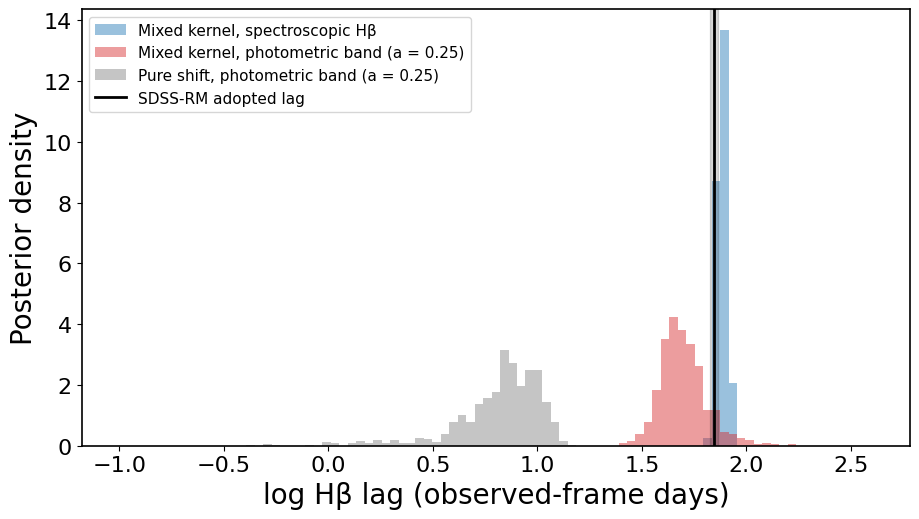

In [11]:
lags = {
    "Mixed kernel, spectroscopic Hβ": np.exp(np.asarray(mcmc_spec.get_samples()["log_lag"])),
    f"Mixed kernel, photometric band (a = {a_line})": np.exp(np.asarray(mcmc_prm.get_samples()["log_lag"])),
    f"Pure shift, photometric band (a = {a_line})": np.asarray(mcmc_shift.get_samples()["lag"]),
}
fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
bins = np.linspace(-1.0, np.log10(400.0), 90)
for (label, draws), color in zip(lags.items(), ["tab:blue", "tab:red", "0.5"]):
    lo, med, hi = np.percentile(draws, [16, 50, 84])
    print(f"{label:48s} {med:6.1f} +{hi - med:.1f} / -{med - lo:.1f} observed-frame days")
    log_draws = np.log10(np.clip(draws, 10 ** bins[0], None))
    ax.hist(log_draws, bins=bins, density=True, histtype="stepfilled", alpha=0.45, color=color, label=label)
ax.axvspan(np.log10(ref_lag - ref_lo), np.log10(ref_lag + ref_hi), color="k", alpha=0.15)
ax.axvline(np.log10(ref_lag), color="k", lw=2, label="SDSS-RM adopted lag")
ax.set_xlabel("log Hβ lag (observed-frame days)")
ax.set_ylabel("Posterior density")
ax.legend(fontsize=11, loc="upper left");

### 6. Changing the base kernel

The latent driver does not have to be a DRW. Any quasiseparable kernel works: replace `base_kernel` and give priors for its parameters, in the same order as `jax.flatten_util.ravel_pytree(base_kernel)`. For an SHO, that order is `(omega, quality, sigma)`. Below we refit the photometric band with an SHO driver (maximum likelihood only, to keep the notebook short).

In [12]:
%%time
def mixed_params_sho():
    log_omega = numpyro.sample("log_omega", dist.Uniform(jnp.log(2 * jnp.pi / 5000.0), jnp.log(2 * jnp.pi / 20.0)))
    log_quality = numpyro.sample("log_quality", dist.Uniform(jnp.log(0.05), jnp.log(5.0)))
    log_sigma = numpyro.sample("log_sigma", dist.Uniform(jnp.log(0.01), jnp.log(2.0)))
    log_kernel_param = jnp.stack([log_omega, log_quality, log_sigma])
    numpyro.deterministic("log_kernel_param", log_kernel_param)
    return {
        "log_kernel_param": log_kernel_param,
        "log_lag": uniform("log_lag"),
        "log_amp_blr": uniform("log_amp_blr"),
        "log_amp_cont": uniform("log_amp_cont"),
        "log_jitter": uniform("log_jitter", (2,)),
    }


m_prm_sho = build_mixed_model(ts_prm, ys_prm, es_prm, SHO(omega=0.01, quality=0.5, sigma=0.1))
best_sho, ll_sho = random_search(m_prm_sho, mixed_params_sho, jax.random.PRNGKey(0), 1000, 5)
best_drw_ll = float(m_prm.log_prob(best_prm))
print(f"SHO driver: max-likelihood lag = {float(jnp.exp(best_sho['log_lag'])):.1f} observed-frame days, "
      f"log L = {float(ll_sho):.1f}  (DRW driver: log L = {best_drw_ll:.1f})")

SHO driver: max-likelihood lag = 54.1 observed-frame days, log L = 1297.4  (DRW driver: log L = 1292.1)
CPU times: user 33.8 s, sys: 1.71 s, total: 35.6 s
Wall time: 30.8 s


### 7. Notes

- **Erlang order.** $K$ sets the shape of the BLR response (fractional rms width $1/\sqrt{K}$). Change `ERLANG_ORDER` to test it; larger $K$ adds states and cost.
- **Amplitudes.** $r_b/c_b$ is the BLR-to-continuum ratio of *variability* amplitudes, not of mean fluxes. For the synthetic band, $r_1/c_1 \approx a\,\sigma_{H\beta}/\sigma_C$, where $\sigma$ is each light curve's fractional variability. In RM160 the spectroscopic fit gives $\sigma_{H\beta}/\sigma_C \approx 1.5$ (the SDSS-RM continuum includes non-variable host light), so $r_1/c_1$ comes out larger than $a$.
- **Many bands.** Nothing here is limited to two bands: give each band its own $c_b$ and $r_b$, e.g., a light curve in each filter of a multi-band survey, where only the filters containing strong lines need $r_b>0$. A per-band lag needs one Erlang chain per lag; this notebook shares one lag across bands.
- **Real photometric data.** The synthetic band here keeps SDSS-RM's dense cadence and ~1% errors, and its line contribution is known exactly. Real photometric surveys have sparser seasons, noisier photometry, and host-galaxy light, and are much harder.
- **Nested sampling.** For the most reliable results, use nested sampling (e.g., `numpyro.contrib.nested_sampling.NestedSampler`) instead of NUTS. It explores multimodal lag posteriors more robustly and gives the Bayesian evidence for comparing models (e.g., pure shift vs. Erlang, or different Erlang orders). It can be much slower, especially with many nuisance parameters.

### 8. Note on disk lags

We assume no continuum (disk) lags between bands: the continuum part of every band is the driver $x(t)$ itself.